# 12 · Drift Detection

Monitor whether incoming data still looks like the data the models were trained on, using the Population Stability Index (PSI) and the Kolmogorov-Smirnov test.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


## 1. PSI intuition

In [2]:
from src.monitoring.drift import psi, drift_report, error_drift
rng = np.random.default_rng(0)
ref = rng.normal(0, 1, 5000)
shifts = [0, 0.1, 0.25, 0.5, 1.0, 1.5]
pd.Series({f"mean shift {s}": round(psi(ref, rng.normal(s, 1, 5000)), 3) for s in shifts}).to_frame("PSI")

,PSI
mean shift 0,0.005
mean shift 0.1,0.015
mean shift 0.25,0.064
mean shift 0.5,0.250
mean shift 1.0,0.929
mean shift 1.5,2.023


Rule of thumb: **< 0.10 stable · 0.10-0.25 moderate · > 0.25 significant**.

## 2. Real data: first 12 months vs. most recent 90 days

In [3]:
end = tx.order_date.max()
ref_tx = tx[tx.order_date < tx.order_date.min() + pd.Timedelta(days=365)]
cur_tx = tx[tx.order_date > end - pd.Timedelta(days=90)]
rep = drift_report(ref_tx, cur_tx, ["quantity", "unit_price", "revenue"]); rep

,feature,psi,ks_stat,ks_pvalue,status
0,unit_price,0.0128,0.0476,1.191263e-10,OK
1,revenue,0.0066,0.0385,4.027313e-07,OK
2,quantity,0.0014,0.0180,6.903882e-02,OK


## 3. Customer-feature drift (what the churn model sees)

In [4]:
from src.churn.model import build_features
f_ref = build_features(tx, customers, end - pd.Timedelta(days=180))
f_cur = build_features(tx, customers, end + pd.Timedelta(days=1))
f_ref, f_cur = (f[f.recency <= ACTIVE_WINDOW_DAYS] for f in (f_ref, f_cur))
rep2 = drift_report(f_ref, f_cur, ["recency", "frequency", "monetary", "avg_order_value", "orders_30d", "orders_90d"]); rep2

,feature,psi,ks_stat,ks_pvalue,status
0,monetary,0.1115,0.1496,3.626238e-11,WARN
1,frequency,0.1110,0.1405,6.540703e-10,WARN
2,recency,0.0330,0.0593,4.039918e-02,OK
3,orders_90d,0.0247,0.0467,1.749509e-01,OK
4,avg_order_value,0.0205,0.0584,4.524858e-02,OK
5,orders_30d,0.0151,0.0179,9.928952e-01,OK


## 4. Simulated incident: a +25% price shock
Does the monitor catch it?

In [5]:
shock = cur_tx.assign(unit_price=cur_tx.unit_price * 1.25, revenue=cur_tx.revenue * 1.25)
drift_report(ref_tx, shock, ["quantity", "unit_price", "revenue"])

,feature,psi,ks_stat,ks_pvalue,status
0,revenue,0.4698,0.1933,1.943176e-170,ALERT
1,unit_price,0.3917,0.1869,2.138251e-159,ALERT
2,quantity,0.0014,0.0180,6.903882e-02,OK


## 5. Model-performance drift (forecast error control chart)

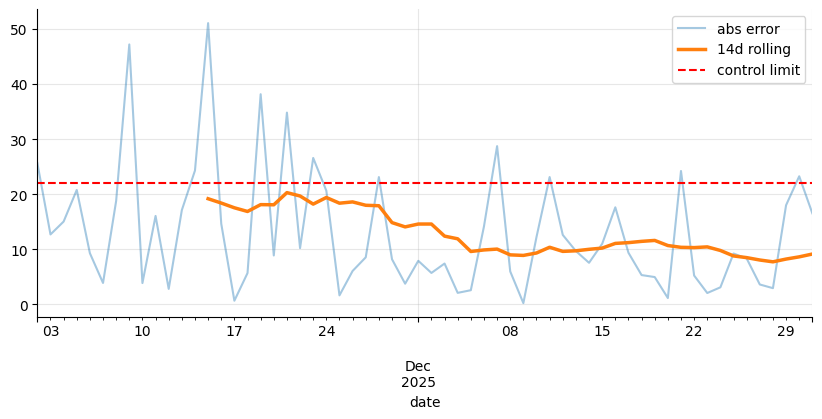

days above control limit: 0


In [6]:
err = pd.read_csv(PROCESSED_DIR / "drift_forecast_error.csv", parse_dates=["date"]).set_index("date")
ax = err["abs_error"].plot(alpha=.4, label="abs error"); err["rolling_error"].plot(ax=ax, lw=2.5, label="14d rolling")
err["upper_limit"].plot(ax=ax, color="r", ls="--", label="control limit"); plt.legend(); plt.show()
print("days above control limit:", int(err.breach.sum()))

## 6. Retraining policy (used in MLOps / CI)
1. Any feature with **ALERT** (PSI ≥ 0.25) → trigger retraining.
2. Rolling forecast error above the control limit for 7+ days → retrain forecasters.
3. Otherwise retrain on the normal weekly schedule.